In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [3]:
filepath = "../data/hotel_bookings_cleaned.csv"
try:
    df = pd.read_csv(filepath)
    print("Dataset Loaded Successfully")
except:
    print("Could not laod data")


Dataset Loaded Successfully


In [4]:
df.head()


,is_canceled,lead_time,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,city,total_guests,total_nights,hotel_type
0,0,342,July,30,27,0,0,2,0.0,0,...,No Deposit,0,Transient,0.0,0,0,Chandigarh,2.0,0,Resort Hotel
1,0,737,April,17,28,0,0,2,0.0,0,...,No Deposit,0,Transient,0.0,0,0,Mumbai,2.0,0,Resort Hotel
2,0,7,September,37,10,0,1,1,0.0,0,...,No Deposit,0,Transient,75.0,0,0,Delhi,1.0,1,Resort Hotel
3,0,13,August,33,14,0,1,1,0.0,0,...,No Deposit,0,Transient,75.0,0,0,Kolkata,1.0,1,Resort Hotel
4,0,14,September,37,14,0,2,2,0.0,0,...,No Deposit,0,Transient,98.0,0,1,Lucknow,2.0,2,Resort Hotel


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119144 entries, 0 to 119143
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   is_canceled                     119144 non-null  int64  
 1   lead_time                       119144 non-null  int64  
 2   arrival_date_month              119144 non-null  object 
 3   arrival_date_week_number        119144 non-null  int64  
 4   arrival_date_day_of_month       119144 non-null  int64  
 5   stays_in_weekend_nights         119144 non-null  int64  
 6   stays_in_week_nights            119144 non-null  int64  
 7   adults                          119144 non-null  int64  
 8   children                        119144 non-null  float64
 9   babies                          119144 non-null  int64  
 10  meal                            119144 non-null  object 
 11  country                         119144 non-null  object 
 12  market_segment  

In [6]:
df = df.drop(columns=['arrival_date_month'])

object_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

df_encoded = pd.get_dummies(df, columns=object_cols, drop_first=False, dtype=int)

print("Categorical Columns Found:", object_cols)
print("\nEncoded DataFrame:")
display(df_encoded.head())

Categorical Columns Found: ['meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'city', 'hotel_type']

Encoded DataFrame:


,is_canceled,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,city_Hyderabad,city_Indore,city_Jaipur,city_Kochi,city_Kolkata,city_Lucknow,city_Mumbai,city_Pune,hotel_type_City Hotel,hotel_type_Resort Hotel
0,0,342,30,27,0,0,2,0.0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0,737,17,28,0,0,2,0.0,0,0,...,0,0,0,0,0,0,1,0,0,1
2,0,7,37,10,0,1,1,0.0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,0,13,33,14,0,1,1,0.0,0,0,...,0,0,0,0,1,0,0,0,0,1
4,0,14,37,14,0,2,2,0.0,0,0,...,0,0,0,0,0,1,0,0,0,1


In [7]:
df_encoded.columns

Index(['is_canceled', 'lead_time', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies',
       'is_repeated_guest',
       ...
       'city_Hyderabad', 'city_Indore', 'city_Jaipur', 'city_Kochi',
       'city_Kolkata', 'city_Lucknow', 'city_Mumbai', 'city_Pune',
       'hotel_type_City Hotel', 'hotel_type_Resort Hotel'],
      dtype='object', length=110)

In [8]:
X = df_encoded.drop(columns=['is_canceled'])
y = df_encoded['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
df_encoded.describe()

,is_canceled,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,...,city_Hyderabad,city_Indore,city_Jaipur,city_Kochi,city_Kolkata,city_Lucknow,city_Mumbai,city_Pune,hotel_type_City Hotel,hotel_type_Resort Hotel
count,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.00000,119144.000000,119144.000000,119144.000000,...,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000,119144.000000
mean,0.370543,104.065492,26.372365,15.723671,0.927264,2.499522,1.85933,0.104101,0.007965,0.031516,...,0.066869,0.065534,0.067297,0.066147,0.066818,0.065920,0.066415,0.066961,0.663919,0.336081
std,0.482952,106.851006,15.020828,8.804389,0.995199,1.897427,0.57521,0.398938,0.097536,0.174710,...,0.249795,0.247467,0.250536,0.248540,0.249708,0.248144,0.249008,0.249955,0.472369,0.472369
min,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,18.000000,13.000000,8.000000,0.000000,1.000000,2.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,69.000000,26.000000,16.000000,1.000000,2.000000,2.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,1.000000,160.000000,39.000000,23.000000,2.000000,3.000000,2.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,1.000000,737.000000,52.000000,31.000000,19.000000,50.000000,55.00000,10.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
models = {
    "Logistic Regression": (LogisticRegression(random_state=42), True),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), False),
    "K-Nearest Neighbors": (KNeighborsClassifier(n_neighbors=5), True)
}
results = {}

for name, (model, requires_scaling) in models.items():
    # Use scaled data for Logistic Regression & KNN, raw data for Decision Tree
    X_tr = X_train_scaled if requires_scaling else X_train
    X_te = X_test_scaled if requires_scaling else X_test
    
    # Train model
    model.fit(X_tr, y_train)
    
    # Make predictions
    y_pred = model.predict(X_te)
    
    # Calculate accuracy
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"==========================================")
    print(f" Model: {name}")
    print(f" Accuracy: {acc:.4f}")
    print(f"==========================================")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\n")

 Model: Logistic Regression
 Accuracy: 0.8114
Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86     14999
           1       0.81      0.64      0.72      8830

    accuracy                           0.81     23829
   macro avg       0.81      0.78      0.79     23829
weighted avg       0.81      0.81      0.81     23829

Confusion Matrix:
[[13652  1347]
 [ 3147  5683]]


 Model: Decision Tree
 Accuracy: 0.8165
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.85      0.85     14999
           1       0.75      0.76      0.75      8830

    accuracy                           0.82     23829
   macro avg       0.80      0.80      0.80     23829
weighted avg       0.82      0.82      0.82     23829

Confusion Matrix:
[[12750  2249]
 [ 2123  6707]]


 Model: K-Nearest Neighbors
 Accuracy: 0.7794
Classification Report:
              precision    recall  f1-score

In [12]:
summary_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])#, 'Precision', 'Recall', 'f1-score'])
print("Final Summary ---------------")
print(summary_df.sort_values(by='Accuracy', ascending=False).to_string(index=False))

Final Summary ---------------
              Model  Accuracy
      Decision Tree  0.816526
Logistic Regression  0.811406
K-Nearest Neighbors  0.779386


# Experiments: tuning, training-set size, train/test splits

**Definitions used throughout**
- *Training fraction* = the share of the **training pool** (what's left after the test split) that the model is fitted on.
  The test set stays fixed while the fraction changes, so the numbers are comparable.
- Scaling lives **inside a Pipeline** for Logistic Regression and KNN, so the scaler is re-fitted on whatever
  rows the model sees (no leakage when we change the split or subsample).
- Logistic Regression uses `max_iter=1000` (the original cell used the default 100, which may not fully converge),
  so its baseline number can differ slightly from the earlier cell.
- None of these three models has a *learning rate* in its standard sklearn form. "Training at different rates" is covered as different fractions of the training data

In [13]:
# ============================================================
#  EXPERIMENT SETUP
# ============================================================
import time, warnings
from IPython.display import display, clear_output
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, validation_curve
from sklearn.metrics import f1_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid")

SEED = 42
MODEL_NAMES = ["Logistic Regression", "Decision Tree", "K-Nearest Neighbors"]
MODEL_COLORS = {"Logistic Regression": "#4C72B0", "Decision Tree": "#55A868", "K-Nearest Neighbors": "#C44E52"}

# ---- speed knobs --------------------------------------------------------
EVAL_CAP = 10_000      # max rows used when SCORING train / test (None = all rows). KNN scoring is the slow part.
N_REPEATS = 3          # repeats (different seeds) per experiment, used for the error bars
FRACTIONS = np.round(np.arange(0.1, 1.01, 0.1), 2)     # 10%, 20%, ... 100%

# Plain numpy copies so subsampling / scoring is fast
X_all = X.to_numpy(dtype=float)
y_all = y.to_numpy()

DEFAULT_PARAMS = {
    "Logistic Regression": {"C": 1.0, "max_iter": 1000},
    "Decision Tree": {},
    "K-Nearest Neighbors": {"n_neighbors": 5},
}


def build_model(name, params=None):
    """Return an unfitted Pipeline. Step name is always 'clf' so grid keys look like clf__C."""
    params = dict(params or {})
    if name == "Logistic Regression":
        clf = LogisticRegression(random_state=SEED, **{"max_iter": 1000, **params})
        return Pipeline([("scale", StandardScaler()), ("clf", clf)])
    if name == "Decision Tree":
        return Pipeline([("clf", DecisionTreeClassifier(random_state=SEED, **params))])
    if name == "K-Nearest Neighbors":
        return Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_jobs=-1, **params))])
    raise ValueError(name)


def make_split(test_size, seed=SEED):
    return train_test_split(X_all, y_all, test_size=test_size, random_state=seed, stratify=y_all)


def subsample(Xa, ya, frac, seed=SEED):
    """Stratified random subset containing `frac` of the rows."""
    if frac >= 1.0:
        return Xa, ya
    Xs, _, ys, _ = train_test_split(Xa, ya, train_size=float(frac), random_state=seed, stratify=ya)
    return Xs, ys


def eval_idx(n, cap, seed=SEED):
    """Indices of the rows used for scoring (random subset if n > cap)."""
    if cap is None or n <= cap:
        return np.arange(n)
    return np.random.RandomState(seed).choice(n, cap, replace=False)


def run_experiment(param_sets, test_sizes, fractions, n_repeats=N_REPEATS):
    """
    Fit every model on every (test_size, training-fraction, repeat) and record train/test scores.
    param_sets: {"label": {model_name: params_dict}}
    """
    rows = []
    for ts in test_sizes:
        for rep in range(n_repeats):
            seed = SEED + rep
            Xpool, Xte, ypool, yte = make_split(ts, seed)
            te_idx = eval_idx(len(Xte), EVAL_CAP, seed)
            for frac in fractions:
                Xs, ys = subsample(Xpool, ypool, frac, seed)
                tr_idx = eval_idx(len(Xs), EVAL_CAP, seed)
                for pset, pmap in param_sets.items():
                    for name in MODEL_NAMES:
                        t0 = time.time()
                        m = build_model(name, pmap[name]).fit(Xs, ys)
                        fit_s = time.time() - t0
                        p_tr = m.predict(Xs[tr_idx])
                        p_te = m.predict(Xte[te_idx])
                        rows.append(dict(
                            param_set=pset, model=name, test_size=ts, fraction=float(frac), repeat=rep,
                            n_train=len(Xs), fit_s=fit_s,
                            train_acc=accuracy_score(ys[tr_idx], p_tr),
                            test_acc=accuracy_score(yte[te_idx], p_te),
                            test_f1=f1_score(yte[te_idx], p_te)))
        print(f"  test_size={ts:.2f}: {n_repeats} repeat(s) done")
    return pd.DataFrame(rows)

print(f"Rows: {len(X_all):,}   Features: {X_all.shape[1]}   Class balance (canceled=1): {y_all.mean():.1%}")

Rows: 119,144   Features: 109   Class balance (canceled=1): 37.1%


## 1. Hyperparameter tuning

Grid search with stratified cross-validation, run **only on the training pool** (never on the held-out test rows).
To keep KNN affordable the search uses a subsample (`TUNE_ROWS`). Optimal depth / `k` often shifts a bit with more data,
so treat the result as a strong starting point rather than a final answer.

In [ ]:
TUNE_ROWS = 20_000          # rows used for the search (raise for a more faithful search, slower)
TUNE_SCORING = "accuracy"   # try "f1" or "roc_auc" - accuracy can hide poor recall on the minority class
CV_FOLDS = 3

Xpool, Xhold, ypool, yhold = make_split(0.2)
Xtune, ytune = subsample(Xpool, ypool, min(1.0, TUNE_ROWS / len(Xpool)))
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)

param_grids = {
    "Logistic Regression": {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
                            "clf__class_weight": [None, "balanced"]},
    "Decision Tree": {"clf__max_depth": [3, 5, 8, 12, 16, 24, None],
                      "clf__min_samples_leaf": [1, 5, 20, 50],
                      "clf__criterion": ["gini", "entropy"]},
    "K-Nearest Neighbors": {"clf__n_neighbors": [3, 5, 9, 15, 25, 41],
                            "clf__weights": ["uniform", "distance"],
                            "clf__p": [1, 2]},
}

tuned_params, tuning_results = {}, {}
for name in MODEL_NAMES:
    t0 = time.time()
    gs = GridSearchCV(build_model(name), param_grids[name], cv=cv, scoring=TUNE_SCORING,
                      n_jobs=-1, refit=False, return_train_score=True)
    gs.fit(Xtune, ytune)
    tuned_params[name] = {k.split("__", 1)[1]: v for k, v in gs.best_params_.items()}
    res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
    tuning_results[name] = res
    print(f"\n=== {name}  ({time.time() - t0:.0f}s) ===")
    print(f"best CV {TUNE_SCORING}: {gs.best_score_:.4f}   best params: {tuned_params[name]}")
    cols = ["mean_train_score", "mean_test_score", "std_test_score"] + [c for c in res.columns if c.startswith("param_")]
    display(res[cols].head(5).round(4).reset_index(drop=True))


=== Logistic Regression  (3s) ===
best CV accuracy: 0.8055   best params: {'C': 10, 'class_weight': None}


,mean_train_score,mean_test_score,std_test_score,param_clf__C,param_clf__class_weight
0,0.8098,0.8055,0.0009,10.00,None
1,0.8099,0.8054,0.0008,100.00,None
2,0.8098,0.8054,0.0007,1.00,None
3,0.8091,0.8046,0.0001,0.10,None
4,0.8066,0.8019,0.0005,0.01,None



=== Decision Tree  (2s) ===
best CV accuracy: 0.8207   best params: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 5}


,mean_train_score,mean_test_score,std_test_score,param_clf__criterion,param_clf__max_depth,param_clf__min_samples_leaf
0,0.8533,0.8207,0.0016,gini,12,5
1,0.8331,0.8205,0.0041,entropy,12,50
2,0.8318,0.8205,0.0021,gini,12,50
3,0.8352,0.8205,0.0022,entropy,16,50
4,0.8354,0.8200,0.0023,entropy,None,50


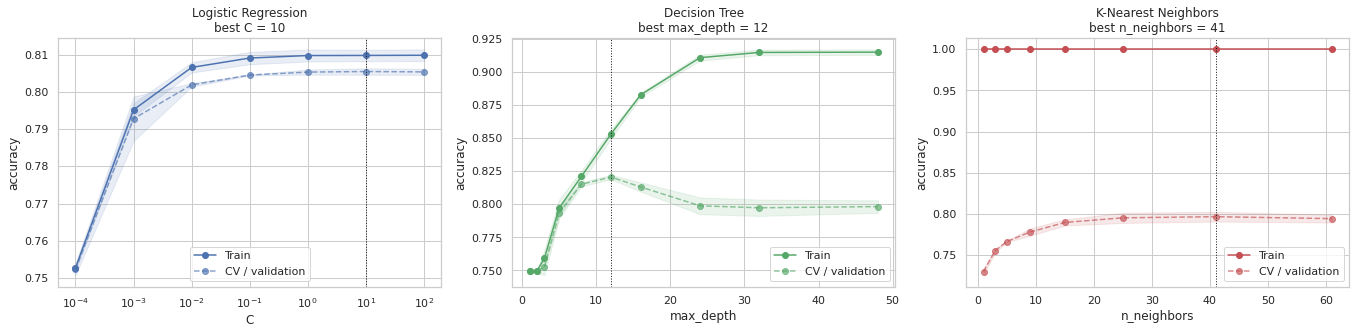

In [ ]:
# Validation curves: how train vs cross-validated score move as ONE hyperparameter changes
# (a widening gap between the lines = overfitting)
vc_specs = {
    "Logistic Regression": ("clf__C", [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100], True),
    "Decision Tree": ("clf__max_depth", [1, 2, 3, 5, 8, 12, 16, 24, 32, 48], False),
    "K-Nearest Neighbors": ("clf__n_neighbors", [1, 3, 5, 9, 15, 25, 41, 61], False),
}

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, name in zip(axes, MODEL_NAMES):
    pname, values, logx = vc_specs[name]
    tr, va = validation_curve(build_model(name, tuned_params[name]), Xtune, ytune, param_name=pname,
                              param_range=values, cv=cv, scoring=TUNE_SCORING, n_jobs=-1)
    c = MODEL_COLORS[name]
    for scores, label, ls in [(tr, "Train", "-"), (va, "CV / validation", "--")]:
        mu, sd = scores.mean(1), scores.std(1)
        ax.plot(values, mu, ls, marker="o", color=c, alpha=1 if label == "Train" else 0.65, label=label)
        ax.fill_between(values, mu - sd, mu + sd, color=c, alpha=0.12)
    best = values[int(va.mean(1).argmax())]
    ax.axvline(best, color="k", ls=":", lw=1)
    if logx:
        ax.set_xscale("log")
    ax.set_title(f"{name}\nbest {pname.split('__')[1]} = {best}")
    ax.set_xlabel(pname.split("__")[1]); ax.set_ylabel(TUNE_SCORING); ax.legend()
plt.tight_layout(); plt.show()

## 2. Train on 10% -> 100% of the training data

Top row: grouped bars (train vs test) for each training fraction, with error bars = std across `N_REPEATS` seeds.
Bottom row: the same numbers as lines so the train/test gap is easy to read.
We run it twice, with **default** and **tuned** hyperparameters. (Bar y-axes are truncated to make differences visible.)

Running training-fraction experiment (80/20 split)...
  test_size=0.20: 3 repeat(s) done


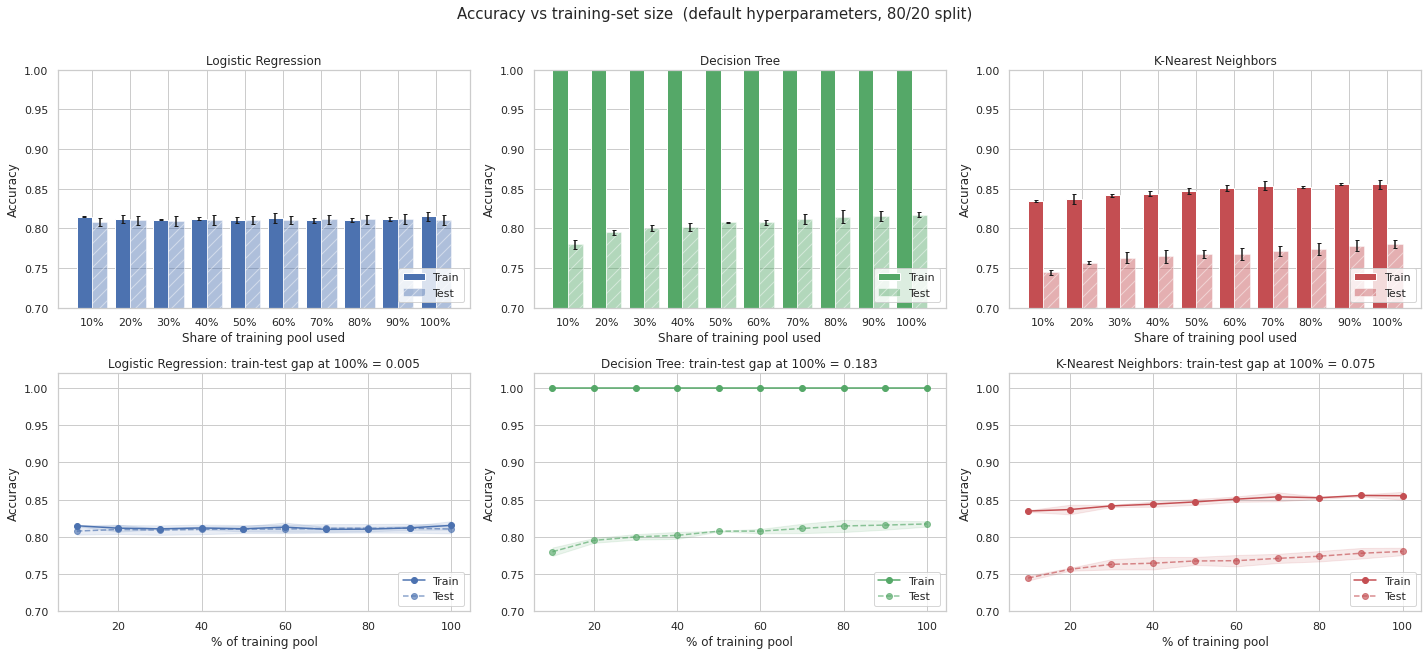

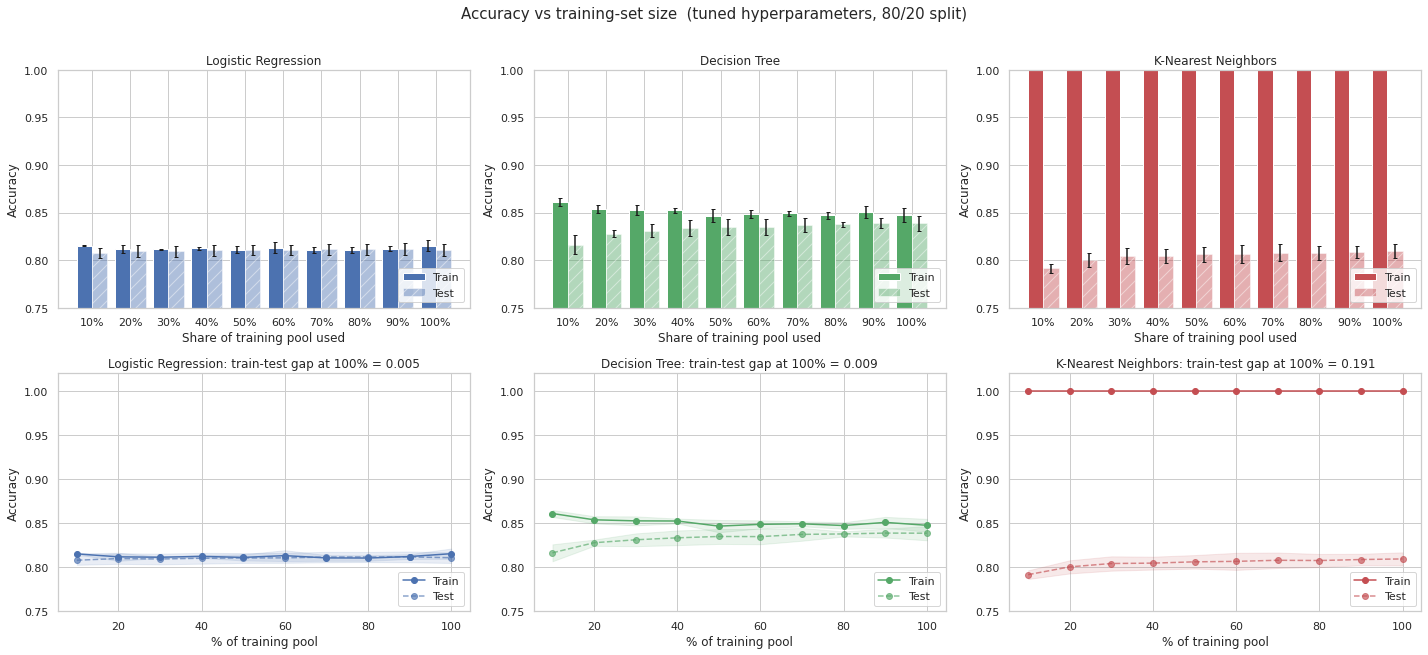

fraction                          0.1     0.2     0.3     0.4     0.5     0.6  \
param_set model                                                                 
default   Decision Tree        0.7801  0.7953  0.8000  0.8020  0.8077  0.8078   
          K-Nearest Neighbors  0.7447  0.7564  0.7631  0.7646  0.7676  0.7680   
          Logistic Regression  0.8078  0.8100  0.8092  0.8101  0.8105  0.8106   
tuned     Decision Tree        0.8163  0.8278  0.8311  0.8333  0.8349  0.8347   
          K-Nearest Neighbors  0.7916  0.8004  0.8042  0.8046  0.8061  0.8066   
          Logistic Regression  0.8079  0.8098  0.8093  0.8102  0.8104  0.8106   

fraction                          0.7     0.8     0.9     1.0  
param_set model                                                
default   Decision Tree        0.8114  0.8147  0.8159  0.8174  
          K-Nearest Neighbors  0.7711  0.7740  0.7780  0.7804  
          Logistic Regression  0.8115  0.8116  0.8116  0.8106  
tuned     Decision Tree        0.8372  0.8377  0.8387  0.8386  
          K-Nearest Neighbors  0.8079  0.8076  0.8087  0.8094  
          Logistic Regression  0.8115  0.8116  0.8117  0.8108

Default vs tuned at 100% of the training pool:


train_acc  test_acc  test_f1   fit_s
model               param_set                                      
Decision Tree       default       1.0000    0.8174   0.7544  1.1402
                    tuned         0.8475    0.8386   0.7716  0.7824
K-Nearest Neighbors default       0.8553    0.7804   0.6913  0.0867
                    tuned         1.0000    0.8094   0.7097  0.0823
Logistic Regression default       0.8155    0.8106   0.7152  0.6151
                    tuned         0.8153    0.8108   0.7154  0.6366

In [ ]:
def plot_fraction_results(df, title):
    agg = df.groupby(["model", "fraction"])[["train_acc", "test_acc"]].agg(["mean", "std"]).fillna(0)
    lo = np.floor((min(agg[("train_acc", "mean")].min(), agg[("test_acc", "mean")].min()) - 0.03) * 20) / 20
    fig, axes = plt.subplots(2, 3, figsize=(20, 9))
    for j, name in enumerate(MODEL_NAMES):
        sub, c = agg.loc[name], MODEL_COLORS[name]
        fr = sub.index.to_numpy(); x = np.arange(len(fr)); w = 0.4
        ax = axes[0, j]
        ax.bar(x - w/2, sub[("train_acc", "mean")], w, yerr=sub[("train_acc", "std")], capsize=2, color=c, label="Train")
        ax.bar(x + w/2, sub[("test_acc", "mean")], w, yerr=sub[("test_acc", "std")], capsize=2, color=c,
               alpha=0.45, hatch="//", edgecolor="white", label="Test")
        ax.set_xticks(x); ax.set_xticklabels([f"{f:.0%}" for f in fr]); ax.set_ylim(lo, 1.0)
        ax.set_title(name); ax.set_xlabel("Share of training pool used"); ax.set_ylabel("Accuracy"); ax.legend(loc="lower right")
        ax = axes[1, j]
        for col, label, ls in [("train_acc", "Train", "-"), ("test_acc", "Test", "--")]:
            mu, sd = sub[(col, "mean")].to_numpy(), sub[(col, "std")].to_numpy()
            ax.plot(fr * 100, mu, ls, marker="o", color=c, label=label, alpha=1 if label == "Train" else 0.65)
            ax.fill_between(fr * 100, mu - sd, mu + sd, color=c, alpha=0.12)
        gap = sub[("train_acc", "mean")].iloc[-1] - sub[("test_acc", "mean")].iloc[-1]
        ax.set_title(f"{name}: train-test gap at 100% = {gap:.3f}")
        ax.set_xlabel("% of training pool"); ax.set_ylabel("Accuracy"); ax.set_ylim(lo, 1.02); ax.legend(loc="lower right")
    fig.suptitle(title, fontsize=15, y=1.01)
    plt.tight_layout(); plt.show()


param_sets = {"default": DEFAULT_PARAMS, "tuned": tuned_params}
print("Running training-fraction experiment (80/20 split)...")
exp1 = run_experiment(param_sets, test_sizes=[0.2], fractions=FRACTIONS)

for pset in param_sets:
    plot_fraction_results(exp1[exp1.param_set == pset], f"Accuracy vs training-set size  ({pset} hyperparameters, 80/20 split)")

# Numeric tables
tbl = exp1.groupby(["param_set", "model", "fraction"])[["train_acc", "test_acc", "test_f1", "fit_s"]].mean().round(4)
display(tbl.test_acc.unstack("fraction"))
print("Default vs tuned at 100% of the training pool:")
display(exp1[exp1.fraction == 1.0].groupby(["model", "param_set"])[["train_acc", "test_acc", "test_f1", "fit_s"]].mean().round(4))

## 3. Same experiment with different train/test splits

Test sizes 10% to 50% (so train/test = 90/10 ... 50/50), each crossed with the 10% -> 100% training fractions, using the tuned hyperparameters.
Uses 1 repeat per cell by default (`N_REPEATS_SPLITS`) to keep runtime reasonable.

Running split experiment...
  test_size=0.10: 1 repeat(s) done
  test_size=0.20: 1 repeat(s) done
  test_size=0.30: 1 repeat(s) done
  test_size=0.40: 1 repeat(s) done
  test_size=0.50: 1 repeat(s) done


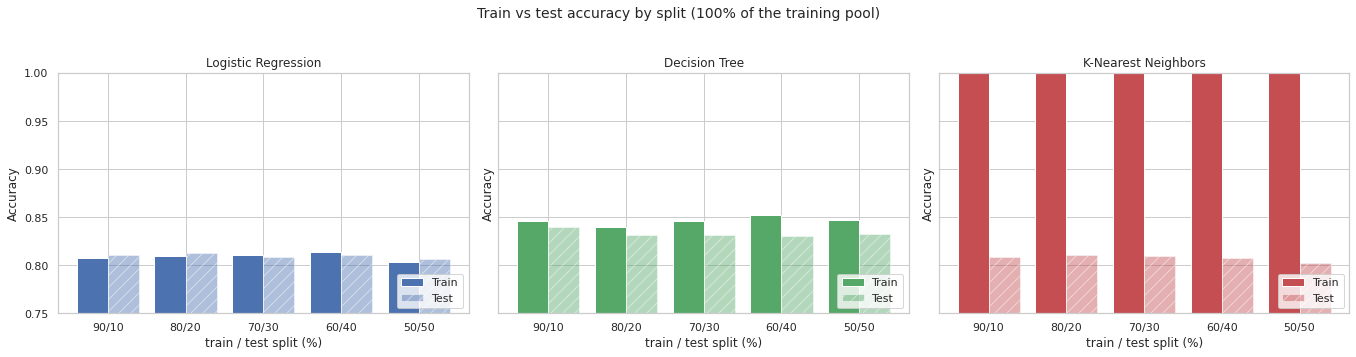

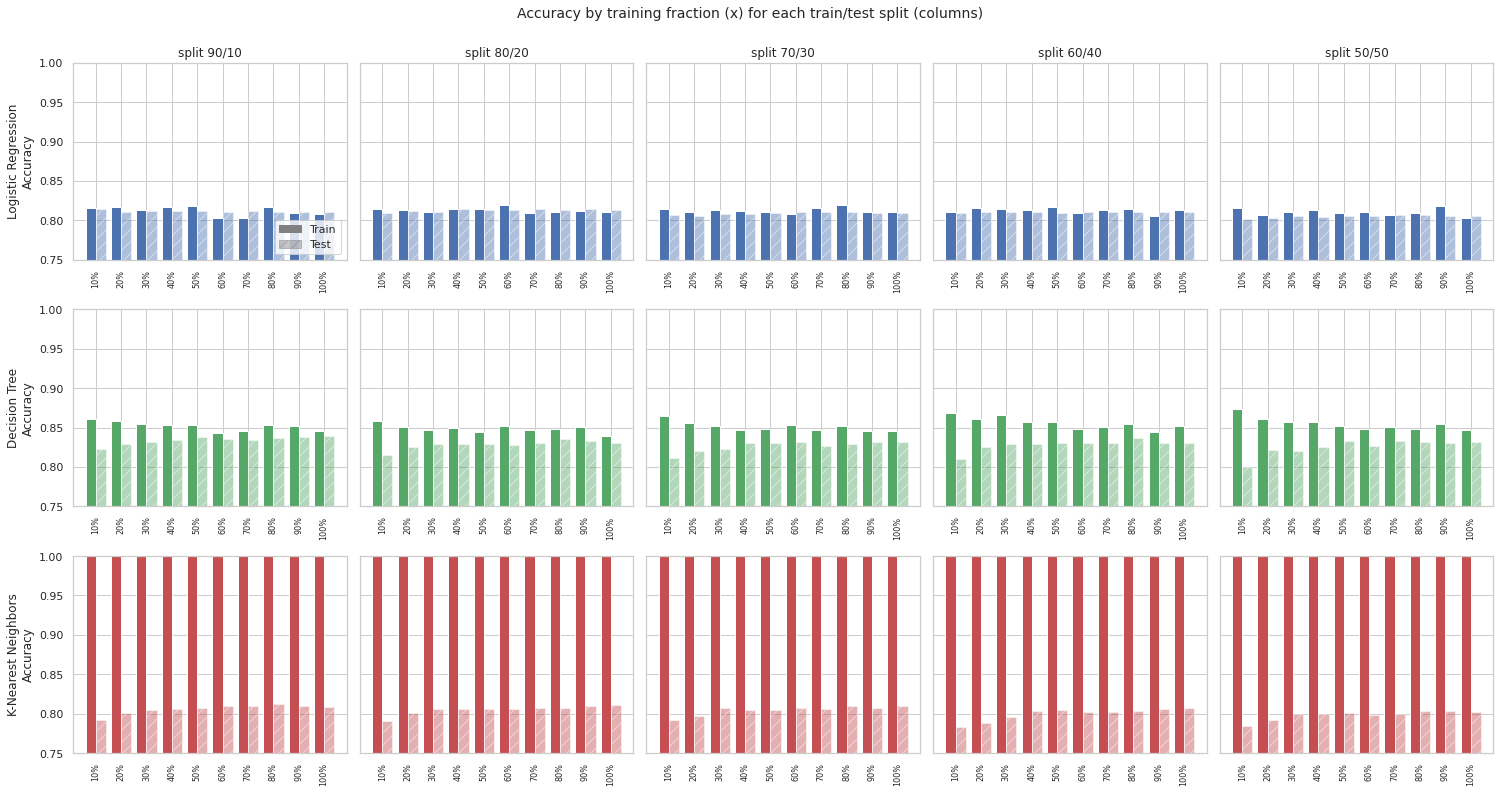

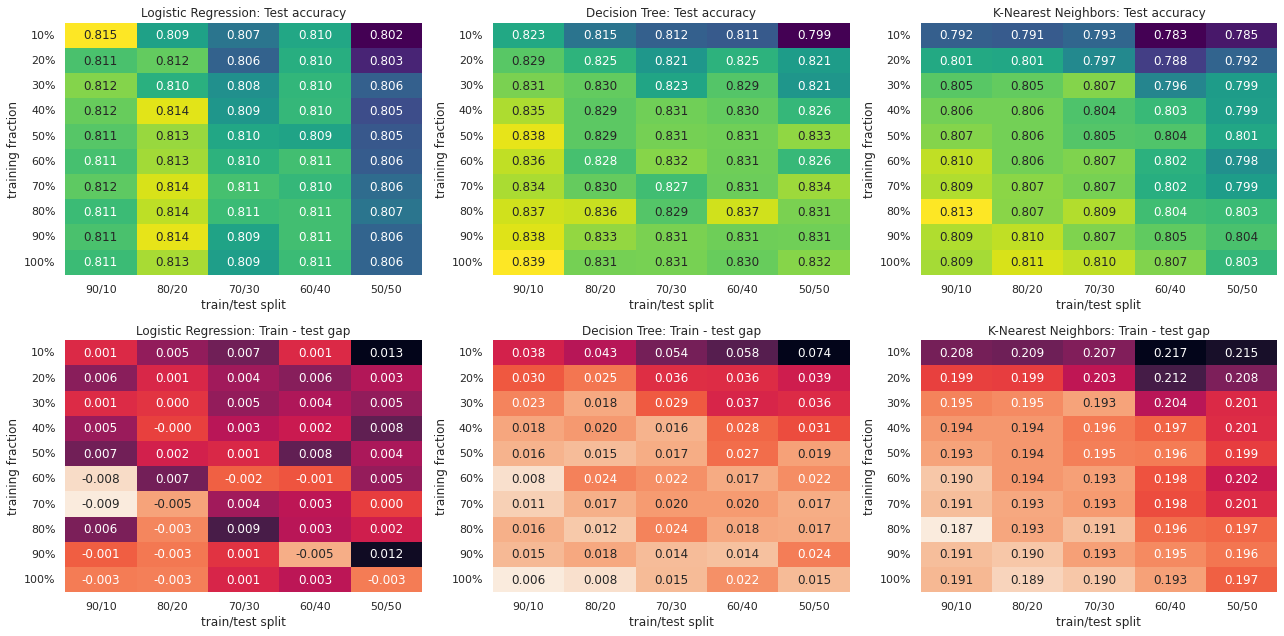

Top 10 (model, split, fraction) combinations by test accuracy:


,model,test_size,fraction,n_train,train_acc,test_acc,test_f1,fit_s
28,Decision Tree,0.1,1.0,107229,0.8456,0.8394,0.7751,0.9386
13,Decision Tree,0.1,0.5,53614,0.8539,0.8379,0.7717,0.4221
25,Decision Tree,0.1,0.9,96506,0.8526,0.8375,0.7712,0.8322
22,Decision Tree,0.1,0.8,85783,0.8530,0.8365,0.7716,0.7339
112,Decision Tree,0.4,0.8,57188,0.8545,0.8365,0.7701,0.4342
52,Decision Tree,0.2,0.8,76252,0.8484,0.8361,0.7697,0.5916
16,Decision Tree,0.1,0.6,64337,0.8437,0.8356,0.7673,0.5492
10,Decision Tree,0.1,0.4,42891,0.8528,0.8345,0.7697,0.3089
19,Decision Tree,0.1,0.7,75060,0.8454,0.8344,0.7687,0.6553
139,Decision Tree,0.5,0.7,41700,0.8506,0.8335,0.7652,0.3046


In [ ]:
SPLITS = [0.1, 0.2, 0.3, 0.4, 0.5]      # test-set shares
N_REPEATS_SPLITS = 1

print("Running split experiment...")
exp2 = run_experiment({"tuned": tuned_params}, test_sizes=SPLITS, fractions=FRACTIONS, n_repeats=N_REPEATS_SPLITS)

lo = np.floor((min(exp2.train_acc.min(), exp2.test_acc.min()) - 0.02) * 20) / 20

# --- A) Train vs test at 100% of the training pool, for each split ----------------
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharey=True)
full = exp2[exp2.fraction == 1.0].groupby(["model", "test_size"])[["train_acc", "test_acc"]].mean()
for ax, name in zip(axes, MODEL_NAMES):
    sub, c = full.loc[name], MODEL_COLORS[name]
    x = np.arange(len(sub)); w = 0.4
    ax.bar(x - w/2, sub.train_acc, w, color=c, label="Train")
    ax.bar(x + w/2, sub.test_acc, w, color=c, alpha=0.45, hatch="//", edgecolor="white", label="Test")
    ax.set_xticks(x); ax.set_xticklabels([f"{round((1-t)*100)}/{round(t*100)}" for t in sub.index])
    ax.set_ylim(lo, 1.0); ax.set_title(name); ax.set_xlabel("train / test split (%)"); ax.set_ylabel("Accuracy"); ax.legend(loc="lower right")
fig.suptitle("Train vs test accuracy by split (100% of the training pool)", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

# --- B) Full grid: rows = model, columns = split, bars = training fraction ---------
fig, axes = plt.subplots(3, len(SPLITS), figsize=(4.2 * len(SPLITS), 11), sharey=True)
grid = exp2.groupby(["model", "test_size", "fraction"])[["train_acc", "test_acc"]].mean()
for i, name in enumerate(MODEL_NAMES):
    for j, ts in enumerate(SPLITS):
        ax, sub, c = axes[i, j], grid.loc[(name, ts)], MODEL_COLORS[name]
        x = np.arange(len(sub)); w = 0.4
        ax.bar(x - w/2, sub.train_acc, w, color=c)
        ax.bar(x + w/2, sub.test_acc, w, color=c, alpha=0.45, hatch="//", edgecolor="white")
        ax.set_xticks(x); ax.set_xticklabels([f"{f:.0%}" for f in sub.index], rotation=90, fontsize=8)
        ax.set_ylim(lo, 1.0)
        if i == 0: ax.set_title(f"split {round((1-ts)*100)}/{round(ts*100)}")
        if j == 0: ax.set_ylabel(f"{name}\nAccuracy")
axes[0, 0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="grey", label="Train"),
                           plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.45, hatch="//", label="Test")], loc="lower right")
fig.suptitle("Accuracy by training fraction (x) for each train/test split (columns)", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

# --- C) Heatmaps: test accuracy and overfitting gap --------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for j, name in enumerate(MODEL_NAMES):
    sub = exp2[exp2.model == name].copy()
    sub["gap"] = sub.train_acc - sub.test_acc
    for i, (col, cmap, ttl) in enumerate([("test_acc", "viridis", "Test accuracy"), ("gap", "rocket_r", "Train - test gap")]):
        piv = sub.pivot_table(index="fraction", columns="test_size", values=col)
        piv.index = [f"{f:.0%}" for f in piv.index]; piv.columns = [f"{round((1-t)*100)}/{round(t*100)}" for t in piv.columns]
        sns.heatmap(piv, annot=True, fmt=".3f", cmap=cmap, ax=axes[i, j], cbar=False)
        axes[i, j].set_title(f"{name}: {ttl}"); axes[i, j].set_xlabel("train/test split"); axes[i, j].set_ylabel("training fraction")
plt.tight_layout(); plt.show()

print("Top 10 (model, split, fraction) combinations by test accuracy:")
display(exp2.sort_values("test_acc", ascending=False)[["model", "test_size", "fraction", "n_train", "train_acc", "test_acc", "test_f1", "fit_s"]].head(10).round(4))

In [ ]:
# ============================================================
#  EXPORT CELL - paste as the LAST cell of model_experimentation.ipynb
#  Writes everything the Flask app needs into src/analysis_output/
# ============================================================
import json
from pathlib import Path

OUT_DIR = Path("analysis_output")      # notebook lives in src/, so this is src/analysis_output
OUT_DIR.mkdir(exist_ok=True)


def to_native(v):
    """Make numpy types / None JSON-safe."""
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    return v


# 1) Best hyperparameters + CV scores from the grid search
tuning_rows = []
for name in MODEL_NAMES:
    best = tuning_results[name].iloc[0]          # sorted by rank_test_score
    tuning_rows.append({
        "model": name,
        "scoring": TUNE_SCORING,
        "cv_train_score": round(best["mean_train_score"], 4),
        "cv_test_score": round(best["mean_test_score"], 4),
        "cv_std": round(best["std_test_score"], 4),
        "best_params": json.dumps({k: to_native(v) for k, v in tuned_params[name].items()}),
    })
pd.DataFrame(tuning_rows).to_csv(OUT_DIR / "tuning_results.csv", index=False)

# 2) Default vs tuned at 100% of the training pool (80/20 split)
default_vs_tuned = (
    exp1[exp1.fraction == 1.0]
    .groupby(["model", "param_set"])[["train_acc", "test_acc", "test_f1", "fit_s"]]
    .mean().round(4).reset_index()
)
default_vs_tuned["gap"] = (default_vs_tuned.train_acc - default_vs_tuned.test_acc).round(4)
default_vs_tuned.to_csv(OUT_DIR / "default_vs_tuned.csv", index=False)

# 3) Training-fraction curves (mean + std over repeats)
fraction_results = (
    exp1.groupby(["param_set", "model", "fraction"])[["train_acc", "test_acc", "test_f1", "fit_s"]]
    .agg(["mean", "std"]).fillna(0)
)
fraction_results.columns = ["_".join(c) for c in fraction_results.columns]
fraction_results.round(4).reset_index().to_csv(OUT_DIR / "fraction_results.csv", index=False)

# 4) Train/test split experiment
split_results = (
    exp2.groupby(["model", "test_size", "fraction"])[["n_train", "train_acc", "test_acc", "test_f1", "fit_s"]]
    .mean().round(4).reset_index()
)
split_results["gap"] = (split_results.train_acc - split_results.test_acc).round(4)
split_results.to_csv(OUT_DIR / "split_results.csv", index=False)

print("Saved to", OUT_DIR.resolve())
for f in sorted(OUT_DIR.glob("*.csv")):
    print(" -", f.name)

NameError: name 'MODEL_NAMES' is not defined